# 4.1 Six métriques visuelles + 5 classifieurs : Dataset 2 (1er extrait, 30 000 images)

Même démarche qu'en 3.1 : 6 mesures par image et 5 classifieurs. Même découpage pour tous ; les
hyperparamètres sont choisis par validation croisée sur le train.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

from outils_4 import list_images

warnings.filterwarnings("ignore", message="A worker stopped")  # avertissement joblib sans importance
DOSSIER = "../data/rvl_cdip_filtered_dataset_2"

## Les 6 métriques visuelles de chaque image (environ 3 minutes)

In [2]:
df = list_images(DOSSIER)

lignes = []
for chemin in df["filepath"]:
    image = Image.open(chemin).convert("L")
    pixels = np.array(image, dtype=np.float32)
    largeur, hauteur = image.size
    lignes.append({"width": largeur,
                   "height": hauteur,
                   "brightness": pixels.mean(),
                   "contrast": pixels.std(),
                   "dark_ratio": (pixels < 128).mean(),  # part de pixels sombres, en gros la quantité d'encre
                   "aspect_ratio": largeur / hauteur})

X = pd.DataFrame(lignes)
y = df["label"]
X.head()

,width,height,brightness,contrast,dark_ratio,aspect_ratio
0,777,1000,245.358429,41.451939,0.037450,0.777
1,715,1000,241.333908,44.596489,0.052498,0.715
2,825,1000,235.121185,56.797554,0.077886,0.825
3,754,1000,246.995941,38.859848,0.031034,0.754
4,778,1000,229.836548,65.564491,0.096752,0.778


## Préparation des données (commune aux 5 modèles)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

# SVM et KNN calculent des distances, donc on standardise (fit sur le train seulement)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

resultats = {}
print(f"Train : {len(X_train)} | Test : {len(X_test)}")

Train : 24000 | Test : 6000


## 1. SVM

In [4]:
grid_svm = GridSearchCV(SVC(), {"C": [0.1, 1, 10],
                                "kernel": ["rbf", "linear", "poly"],
                                "gamma": [0.001, 0.1, 0.5]}, cv=5, n_jobs=-1)
grid_svm.fit(X_train_s, y_train)
print("Meilleurs paramètres :", grid_svm.best_params_)
print(f"Score en validation croisée : {grid_svm.best_score_:.3f}")

y_pred = grid_svm.predict(X_test_s)
resultats["SVM"] = accuracy_score(y_test, y_pred)
print(f"Accuracy test : {resultats['SVM']:.3f}")
pd.crosstab(y_test, y_pred, rownames=["réel"], colnames=["prédit"])

Meilleurs paramètres : {'C': 10, 'gamma': 0.5, 'kernel': 'rbf'}
Score en validation croisée : 0.471


Accuracy test : 0.473


prédit,email,form,invoice,presentation,resume,scientific_report
réel,,,,,,
email,791,51,5,5,136,1
form,95,373,158,43,181,191
invoice,129,183,356,57,108,155
presentation,120,214,153,207,139,160
resume,89,89,56,15,706,54
scientific_report,159,111,122,69,116,403


## 2. KNN

k et la distance sont choisis par validation croisée. La courbe donne le score selon k.

Meilleurs paramètres : {'metric': 'manhattan', 'n_neighbors': 29}
Score en validation croisée : 0.473


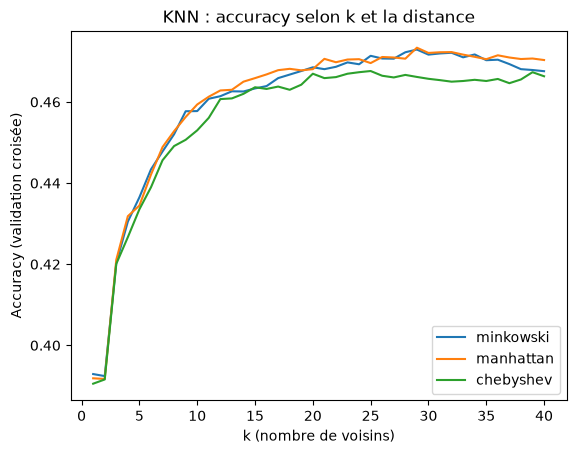

In [5]:
grid_knn = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": range(1, 41),
                                                 "metric": ["minkowski", "manhattan", "chebyshev"]}, cv=5, n_jobs=-1)
grid_knn.fit(X_train_s, y_train)
print("Meilleurs paramètres :", grid_knn.best_params_)
print(f"Score en validation croisée : {grid_knn.best_score_:.3f}")

scores = pd.DataFrame(grid_knn.cv_results_)
for distance in ["minkowski", "manhattan", "chebyshev"]:
    sous_scores = scores[scores["param_metric"] == distance]
    plt.plot(sous_scores["param_n_neighbors"], sous_scores["mean_test_score"], label=distance)
plt.xlabel("k (nombre de voisins)")
plt.ylabel("Accuracy (validation croisée)")
plt.title("KNN : accuracy selon k et la distance")
plt.legend()
plt.show()

In [6]:
y_pred = grid_knn.predict(X_test_s)
resultats["KNN"] = accuracy_score(y_test, y_pred)
print(f"Accuracy test : {resultats['KNN']:.3f}")
pd.crosstab(y_test, y_pred, rownames=["réel"], colnames=["prédit"])

Accuracy test : 0.461


prédit,email,form,invoice,presentation,resume,scientific_report
réel,,,,,,
email,758,58,19,16,129,9
form,80,366,171,100,173,151
invoice,111,189,333,89,120,146
presentation,105,192,172,251,123,150
resume,85,85,64,36,690,49
scientific_report,143,111,123,109,124,370


## 3. Arbre de décision

Deux critères comparés, profondeur 4. Pas besoin de standardiser pour un arbre.

In [7]:
for critere in ["entropy", "gini"]:
    arbre = DecisionTreeClassifier(criterion=critere, max_depth=4, random_state=123)
    arbre.fit(X_train, y_train)
    print(f"Accuracy test ({critere}) : {arbre.score(X_test, y_test):.3f}")

arbre = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=123).fit(X_train, y_train)
y_pred = arbre.predict(X_test)
resultats["Arbre de décision"] = accuracy_score(y_test, y_pred)
pd.crosstab(y_test, y_pred, rownames=["réel"], colnames=["prédit"])

Accuracy test (entropy) : 0.396
Accuracy test (gini) : 0.399


prédit,email,form,invoice,presentation,resume,scientific_report
réel,,,,,,
email,692,209,6,5,77,0
form,44,431,111,12,232,211
invoice,77,271,234,14,137,255
presentation,83,332,140,43,164,231
resume,38,277,70,4,577,43
scientific_report,133,253,90,19,84,401


In [8]:
pd.Series(arbre.feature_importances_, index=X.columns).sort_values(ascending=False)

aspect_ratio    0.424844
contrast        0.376959
width           0.099212
brightness      0.098986
height          0.000000
dark_ratio      0.000000
dtype: float64

## 4. XGBoost

XGBoost veut des classes numérotées, d'où le `LabelEncoder`.

In [9]:
encodeur = LabelEncoder().fit(y_train)

grid_xgb = GridSearchCV(XGBClassifier(eval_metric="mlogloss"),
                        {"n_estimators": [100, 300, 500],
                         "learning_rate": [0.01, 0.05, 0.1],
                         "max_depth": [3, 5, 7],
                         "subsample": [0.7, 0.9, 1.0],
                         "colsample_bytree": [0.7, 0.9, 1.0]},
                        cv=5, scoring="f1_weighted", n_jobs=-1)
grid_xgb.fit(X_train, encodeur.transform(y_train))
print("Meilleurs paramètres :", grid_xgb.best_params_)
print(f"Score en validation croisée (f1) : {grid_xgb.best_score_:.3f}")

y_pred = encodeur.inverse_transform(grid_xgb.predict(X_test))
resultats["XGBoost"] = accuracy_score(y_test, y_pred)
print(f"Accuracy test : {resultats['XGBoost']:.3f}")
pd.crosstab(y_test, y_pred, rownames=["réel"], colnames=["prédit"])

Meilleurs paramètres : {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.7}
Score en validation croisée (f1) : 0.480
Accuracy test : 0.482


prédit,email,form,invoice,presentation,resume,scientific_report
réel,,,,,,
email,765,43,14,23,141,3
form,79,324,155,116,194,173
invoice,115,142,370,92,122,147
presentation,78,146,163,330,141,135
resume,72,87,62,28,716,44
scientific_report,129,98,119,107,137,390


## 5. Random Forest

50 combinaisons d'hyperparamètres tirées au hasard (`RandomizedSearchCV`).

In [10]:
recherche_rf = RandomizedSearchCV(RandomForestClassifier(random_state=321),
                                  {"n_estimators": [100, 300, 500],
                                   "max_depth": [None, 5, 10, 20],
                                   "min_samples_split": [2, 5, 10],
                                   "min_samples_leaf": [1, 2, 4],
                                   "max_features": ["sqrt", "log2", None],
                                   "class_weight": ["balanced", None]},
                                  n_iter=50, cv=5, scoring="f1_weighted", n_jobs=-1, random_state=42)
recherche_rf.fit(X_train, y_train)
print("Meilleurs paramètres :", recherche_rf.best_params_)
print(f"Score en validation croisée (f1) : {recherche_rf.best_score_:.3f}")

y_pred = recherche_rf.predict(X_test)
resultats["Random Forest"] = accuracy_score(y_test, y_pred)
print(f"Accuracy test : {resultats['Random Forest']:.3f}")
pd.crosstab(y_test, y_pred, rownames=["réel"], colnames=["prédit"])

Meilleurs paramètres : {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 20, 'class_weight': 'balanced'}
Score en validation croisée (f1) : 0.473
Accuracy test : 0.477


prédit,email,form,invoice,presentation,resume,scientific_report
réel,,,,,,
email,727,52,31,32,127,20
form,70,343,171,146,156,155
invoice,88,155,378,119,102,146
presentation,62,157,158,354,125,137
resume,62,97,67,49,682,52
scientific_report,107,110,133,132,118,380


## Résumé : accuracy sur le test

In [11]:
pd.Series(resultats, name="accuracy").sort_values(ascending=False).round(3)

XGBoost              0.482
Random Forest        0.477
SVM                  0.473
KNN                  0.461
Arbre de décision    0.396
Name: accuracy, dtype: float64